# Laboratorium 4: SimpleRNN, LSTM, GRU i Conv1D
Porównanie modeli w zadaniu sumowania z opóźnieniem o 8 kroków.

In [ ]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Ziarno:', SEED, '| Urządzenie:', DEVICE)

Ziarno: 0 | Urządzenie: cpu


## 1. Dane i sprawdzenie generatora

In [ ]:
def gen(N, L):
    val = np.random.rand(N, L, 1).astype(np.float32)
    mark = np.zeros((N, L, 1), np.float32)
    y = np.zeros((N, 1), np.float32)
    for i in range(N):
        p = np.random.choice(np.arange(8, L), 2, replace=False)
        mark[i, p, 0] = 1.0
        y[i, 0] = val[i, p - 8, 0].sum()
    x = np.concatenate([val, mark], axis=2)
    return torch.tensor(x).to(DEVICE), torch.tensor(y).to(DEVICE)

xx, yy = gen(1, 20)
poz = np.where(xx[0, :, 1].cpu().numpy() == 1)[0]
wartosci = xx[0, poz - 8, 0].cpu().numpy()
assert np.all(poz >= 8) and len(poz) == 2
assert np.isclose(wartosci.sum(), yy[0, 0].item())
print('Znaczniki:', poz + 1)
print('Wskazywane pozycje:', poz - 7)
print('Wskazywane wartości:', np.round(wartosci, 4))
print('Suma:', round(float(wartosci.sum()), 4), '| Cel:', round(yy[0, 0].item(), 4))

Znaczniki: [13 18]
Wskazywane pozycje: [ 5 10]
Wskazywane wartości: [0.4237 0.3834]
Suma: 0.8071 | Cel: 0.8071


## 2. Modele

In [ ]:
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=32):
        super().__init__()
        self.rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ](
            2, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


class ConvNet(nn.Module):
    def __init__(self, ch=32, dylatacje=(1, 2, 4)):
        super().__init__()
        d1, d2, d3 = dylatacje
        self.net = nn.Sequential(
            nn.Conv1d(2, ch, 3, padding=d1, dilation=d1), nn.ReLU(),
            nn.Conv1d(ch, ch, 3, padding=d2, dilation=d2), nn.ReLU(),
            nn.Conv1d(ch, ch, 3, padding=d3, dilation=d3), nn.ReLU())
        self.fc = nn.Linear(ch, 1)

    def forward(self, x):
        h = self.net(x.transpose(1, 2)).mean(dim=2)
        return self.fc(h)


def licz_parametry(model):
    return sum(p.numel() for p in model.parameters())

## 3. Uczenie i wspólne dane

In [ ]:
EPOKI = 30
N_TRENING = 4000
N_TEST = 800
BATCH = 128
LR = 5e-3


def trenuj(model, Xtr, Ytr, Xte, Yte):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    Lf = nn.MSELoss()
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for ep in range(EPOKI):
        model.train()
        perm = torch.randperm(len(Xtr), device=DEVICE)
        for i in range(0, len(Xtr), BATCH):
            idx = perm[i:i+BATCH]
            opt.zero_grad()
            Lf(model(Xtr[idx]), Ytr[idx]).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    czas = time.perf_counter() - t0
    model.eval()
    with torch.no_grad():
        pred = model(Xte)
        mse = Lf(pred, Yte).item()
    return mse, czas, pred


zbiory = {}
baseline = {}
for L in (50, 100):
    Xtr, Ytr = gen(N_TRENING, L)
    Xte, Yte = gen(N_TEST, L)
    zbiory[L] = (Xtr, Ytr, Xte, Yte)
    baseline[L] = ((Yte - Ytr.mean()) ** 2).mean().item()
    print(f'L={L}: trening {len(Xtr)}, test {len(Xte)}, predykcja stała MSE={baseline[L]:.6f}')

wyniki = {}
predykcje = {}
nazwy = ['SimpleRNN', 'LSTM', 'GRU', 'Conv1D']

L=50: trening 4000, test 800, predykcja stała MSE=0.159836


L=100: trening 4000, test 800, predykcja stała MSE=0.166688


## 4. Porównanie: L = 50

In [ ]:
L = 50
Xtr, Ytr, Xte, Yte = zbiory[L]
for nazwa in nazwy:
    torch.manual_seed(SEED)
    model = ConvNet() if nazwa == 'Conv1D' else RNNNet(
        {'SimpleRNN': 'RNN', 'LSTM': 'LSTM', 'GRU': 'GRU'}[nazwa])
    mse, czas, pred = trenuj(model, Xtr, Ytr, Xte, Yte)
    wyniki[(L, nazwa)] = (mse, czas, licz_parametry(model))
    predykcje[(L, nazwa)] = pred
    print(f'{nazwa:10s} MSE={mse:.6f} czas={czas:.2f}s parametry={licz_parametry(model)}')

SimpleRNN  MSE=0.162088 czas=4.60s parametry=1185


LSTM       MSE=0.163913 czas=7.27s parametry=4641


GRU        MSE=0.144153 czas=11.99s parametry=3489


Conv1D     MSE=0.159730 czas=4.07s parametry=6465


## 5. Porównanie: L = 100

In [ ]:
L = 100
Xtr, Ytr, Xte, Yte = zbiory[L]
for nazwa in nazwy:
    torch.manual_seed(SEED)
    model = ConvNet() if nazwa == 'Conv1D' else RNNNet(
        {'SimpleRNN': 'RNN', 'LSTM': 'LSTM', 'GRU': 'GRU'}[nazwa])
    mse, czas, pred = trenuj(model, Xtr, Ytr, Xte, Yte)
    wyniki[(L, nazwa)] = (mse, czas, licz_parametry(model))
    predykcje[(L, nazwa)] = pred
    print(f'{nazwa:10s} MSE={mse:.6f} czas={czas:.2f}s parametry={licz_parametry(model)}')

SimpleRNN  MSE=0.167085 czas=9.21s parametry=1185


LSTM       MSE=0.166406 czas=10.37s parametry=4641


GRU        MSE=0.166555 czas=25.79s parametry=3489


Conv1D     MSE=0.170251 czas=5.85s parametry=6465


## 6. Dwa dodatkowe warianty: L = 100

In [ ]:
Xtr, Ytr, Xte, Yte = zbiory[100]
warianty = {
    'SimpleRNN (64)': RNNNet('RNN', hidden=64),
    'Conv1D [1,1,1]': ConvNet(dylatacje=(1, 1, 1)),
}
for nazwa, model in warianty.items():
    torch.manual_seed(SEED)
    mse, czas, pred = trenuj(model, Xtr, Ytr, Xte, Yte)
    wyniki[(100, nazwa)] = (mse, czas, licz_parametry(model))
    predykcje[(100, nazwa)] = pred
    print(f'{nazwa:16s} MSE={mse:.6f} czas={czas:.2f}s parametry={licz_parametry(model)}')

R_dyl = 1 + (3 - 1) * (1 + 2 + 4)
R_zwykly = 1 + (3 - 1) * (1 + 1 + 1)
print('Pole recepcyjne: [1,2,4] =', R_dyl, '| [1,1,1] =', R_zwykly)

SimpleRNN (64)   MSE=0.167118 czas=13.25s parametry=4417


Conv1D [1,1,1]   MSE=0.166549 czas=5.82s parametry=6465
Pole recepcyjne: [1,2,4] = 15 | [1,1,1] = 7


## 7. Wyniki i przykład większego błędu

  L Model                Test MSE   Czas [s]  Parametry
 50 SimpleRNN            0.162088       4.60       1185
 50 LSTM                 0.163913       7.27       4641
 50 GRU                  0.144153      11.99       3489
 50 Conv1D               0.159730       4.07       6465
 50 Stała predykcja      0.159836          -          -
100 SimpleRNN            0.167085       9.21       1185
100 LSTM                 0.166406      10.37       4641
100 GRU                  0.166555      25.79       3489
100 Conv1D               0.170251       5.85       6465
100 SimpleRNN (64)       0.167118      13.25       4417
100 Conv1D [1,1,1]       0.166549       5.82       6465
100 Stała predykcja      0.166688          -          -


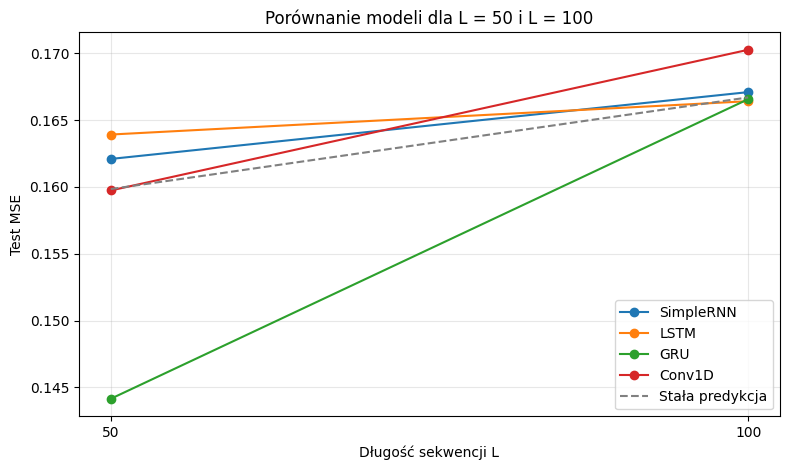

Przykład o dużym błędzie, SimpleRNN, L=100, nr testowy: 581
Znaczniki: [86 92]
Wskazywane pozycje: [78 84]
Wartości: [0.01131 0.04173]
Suma ręczna: 0.05304
Cel: 0.05304 | Predykcja: 1.01771 | Błąd kwadratowy: 0.93059


In [ ]:
print(f"{'L':>3s} {'Model':<17s} {'Test MSE':>11s} {'Czas [s]':>10s} {'Parametry':>10s}")
for L in (50, 100):
    for nazwa in nazwy + (['SimpleRNN (64)', 'Conv1D [1,1,1]'] if L == 100 else []):
        mse, czas, param = wyniki[(L, nazwa)]
        print(f'{L:>3d} {nazwa:<17s} {mse:>11.6f} {czas:>10.2f} {param:>10d}')
    print(f'{L:>3d} {"Stała predykcja":<17s} {baseline[L]:>11.6f} {"-":>10s} {"-":>10s}')

plt.figure(figsize=(8, 4.8))
for nazwa in nazwy:
    plt.plot([50, 100], [wyniki[(L, nazwa)][0] for L in (50, 100)],
             marker='o', label=nazwa)
plt.plot([50, 100], [baseline[L] for L in (50, 100)],
         linestyle='--', color='gray', label='Stała predykcja')
plt.xticks([50, 100])
plt.xlabel('Długość sekwencji L')
plt.ylabel('Test MSE')
plt.title('Porównanie modeli dla L = 50 i L = 100')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Xtr, Ytr, Xte, Yte = zbiory[100]
pred = predykcje[(100, 'SimpleRNN')]
idx = int(torch.argmax((pred - Yte) ** 2).item())
p = torch.where(Xte[idx, :, 1] == 1)[0]
v = Xte[idx, p - 8, 0]
print('Przykład o dużym błędzie, SimpleRNN, L=100, nr testowy:', idx)
print('Znaczniki:', (p + 1).cpu().numpy())
print('Wskazywane pozycje:', (p - 7).cpu().numpy())
print('Wartości:', v.cpu().numpy().round(5))
print('Suma ręczna:', round(float(v.sum().item()), 5))
print('Cel:', round(float(Yte[idx, 0].item()), 5),
      '| Predykcja:', round(float(pred[idx, 0].item()), 5),
      '| Błąd kwadratowy:', round(float((pred[idx, 0] - Yte[idx, 0]).pow(2).item()), 5))